In [1]:
from tda_module.v3_1 import CloudDataManager;  

manager = CloudDataManager()

manager.load_group_from_file("/workspaces/Cellular-TDA/data/Point clouds-selected/control name=embryo_3.csv")
manager.load_group_from_file("/workspaces/Cellular-TDA/data/Point clouds-selected/epha2a hom name=embryo_4.csv")
manager.load_group_from_file("/workspaces/Cellular-TDA/data/Point clouds-selected/control WT  full video centroids_table name=embryo_1.csv")
print("Done loading groups from files.")

Done loading groups from files.


In [2]:
manager.compute_all_persistence_diagrams()
manager.compute_all_persistence_landscapes(n_layers=43, resolution=500) 

In [3]:
import pandas as pd
import numpy as np

# get all control embryos and landscapes vector 
embryo_names = "All"
condition = "control"
properties = [0]

results = manager.build_landscape_matrix( PCA_key=(embryo_names, condition, properties))

#filter for property, id = (embryo_name, time_step), property)
conditionEntriesPerTimeStep = pd.DataFrame(results["matrix"], index=[ timestep for id in results["row_order"] for timestep in [id[0][1]] ])

mean_control_vector = conditionEntriesPerTimeStep.groupby(conditionEntriesPerTimeStep.index).mean()
#dataframe to store the distance from mean control vector for each time step
distance_from_mean_control_vector = np.zeros((len(conditionEntriesPerTimeStep),1))

row_timestep = [ timestep for id in results["row_order"] for timestep in [id[0][1]] ]

for index, (entrie , timestep) in enumerate(zip(distance_from_mean_control_vector, row_timestep)):
    distance_from_mean_control_vector[index] = np.linalg.norm(conditionEntriesPerTimeStep.iloc[index] - mean_control_vector.loc[timestep])

embryo_names = [ id[0][0] for id in results["row_order"] ]
time_steps = [ id[0][1] for id in results["row_order"] ]

table1 = pd.DataFrame( {"embryo_name": embryo_names, "time_step": time_steps, "dist to cv": distance_from_mean_control_vector.reshape(-1) } )

print("Distance from mean control vector table")
print(table1.head())


def comparison_table(PCA_key):
    results = manager.build_landscape_matrix( PCA_key=PCA_key)
    conditionEntriesPerTimeStep = pd.DataFrame(results["matrix"], index=[ timestep for id in results["row_order"] for timestep in [id[0][1]] ])
    mean_vector = conditionEntriesPerTimeStep.groupby(conditionEntriesPerTimeStep.index).mean()
    distance_from_mean_vector = np.zeros((len(conditionEntriesPerTimeStep),1))
    row_timestep = [ timestep for id in results["row_order"] for timestep in [id[0][1]] ]
    for index, (entrie , timestep) in enumerate(zip(distance_from_mean_vector, row_timestep)):
        distance_from_mean_vector[index] = np.linalg.norm(conditionEntriesPerTimeStep.iloc[index] - mean_vector.loc[timestep])
    embryo_names = [ id[0][0] for id in results["row_order"] ]
    time_steps = [ id[0][1] for id in results["row_order"] ]
    table = pd.DataFrame( {"embryo_name": embryo_names, "time_step": time_steps, "dist to mean vector": distance_from_mean_vector.reshape(-1) } )
    return table

Distance from mean control vector table
  embryo_name  time_step    dist to cv
0    embryo_1          0   5593.076250
1    embryo_1          1  10281.373683
2    embryo_1          2   6609.252900
3    embryo_1          3  10177.221820
4    embryo_1          4  13195.943364


In [4]:
control = manager.distance_table_from_control_mean(PCA_key=("All", "control",[0]))
epha2a = manager.distance_table_from_control_mean(PCA_key=("All", "epha2a",[0]))


In [5]:
print(control.head())
print(epha2a.head())

  embryo_name  timestep          dist
0    embryo_1         0   5593.076250
1    embryo_1         1  10281.373683
2    embryo_1         2   6609.252900
3    embryo_1         3  10177.221820
4    embryo_1         4  13195.943364
  embryo_name  timestep          dist
0    embryo_4         0   9258.902046
1    embryo_4         1  25089.420397
2    embryo_4         2   6494.683966
3    embryo_4         3  11859.958631
4    embryo_4         4  12072.303922


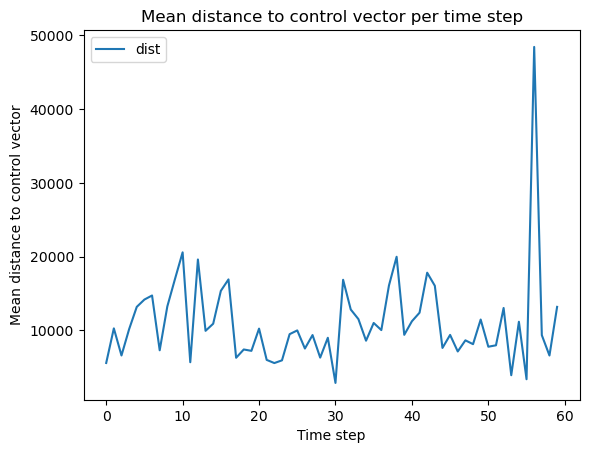

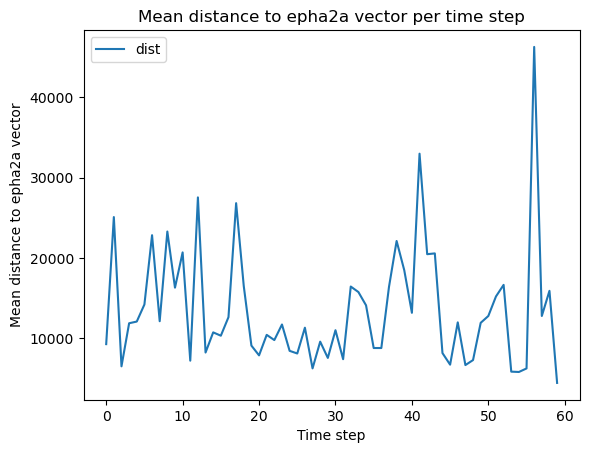

In [6]:
control[["timestep","dist"]].groupby("timestep").mean().plot(title="Mean distance to control vector per time step", ylabel="Mean distance to control vector", xlabel="Time step")
temp =epha2a[["timestep","dist"]].groupby("timestep").mean().plot(title="Mean distance to epha2a vector per time step", ylabel="Mean distance to epha2a vector", xlabel="Time step")